In [462]:
import pandas as pd


In [463]:
teams_data = pd.read_csv("../data/teams_post.csv")
series_data = pd.read_csv("../data/series_post.csv")

Cleaning teams_post - outliers detection 

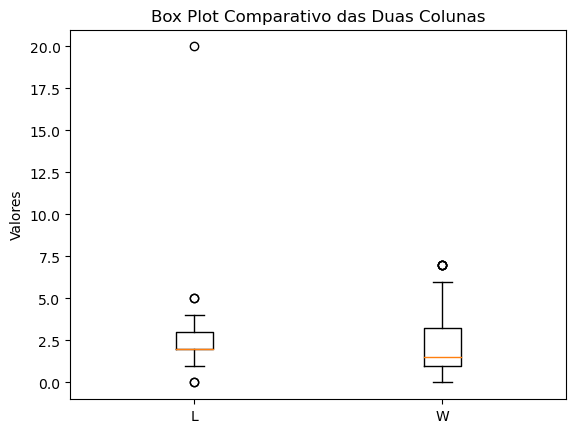

In [464]:
import matplotlib.pyplot as plt
losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()


tendo em conta que é muito improvável haver 20 derrotas, conclui-se a existência  de um outlier

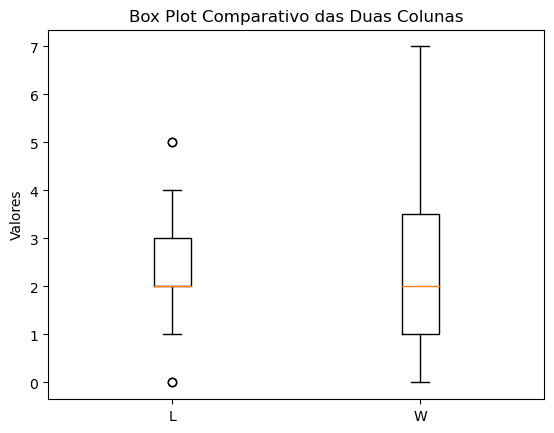

In [465]:
teams_data = teams_data.drop(17)

#filtered_data = teams_data[teams_data['year'] == 3]
#print(filtered_data['L'])

losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()


Comparison of WINS on both tables

In [466]:
# Agrupe os dados por "tmIDWinner" e "year" e calcule a soma de "W" para cada combinação
result = series_data.groupby(['tmIDWinner', 'year'])['W'].sum().reset_index()
result_sorted = result.sort_values(by='year')
print(result_sorted)



   tmIDWinner  year  W
1         CLE     1  2
23        NYL     1  4
16        LAS     1  2
11        HOU     1  6
0         CHA     2  4
30        SAC     2  2
24        NYL     2  2
17        LAS     2  6
25        NYL     3  4
38        UTA     3  2
18        LAS     3  6
39        WAS     3  2
19        LAS     4  4
31        SAC     4  2
2         CON     4  2
6         DET     4  6
37        SEA     5  6
32        SAC     5  2
26        NYL     5  2
3         CON     5  4
12        HOU     6  2
13        IND     6  2
33        SAC     6  7
4         CON     6  4
34        SAC     7  4
7         DET     7  7
20        LAS     7  2
5         CON     7  2
28        PHO     8  7
14        IND     8  2
35        SAS     8  2
8         DET     8  4
27        NYL     9  2
9         DET     9  7
36        SAS     9  4
21        LAS     9  2
10        DET    10  2
15        IND    10  4
22        LAS    10  2
29        PHO    10  7


a teams_post é a soma das vitórias+derrotas destes jogos de playoff que ocorrem anualmente, mas se repararmos alguns dados não estão coerentes em ambas as tabelas como esta linha por ex : 1,"CLE","WNBA",3,3
pois indica que houve 3 vitórias da equipa CLE no ano 1 e na verdade houve apenas duas (apesar de os restantes valores estarem corretos)

daqui conclui-se não só que a teams_post não é necessária não só por ter dados errados mas também por estar tudo (mais explícito na tabela series_post)

Cleaning series_post - outliers detection 

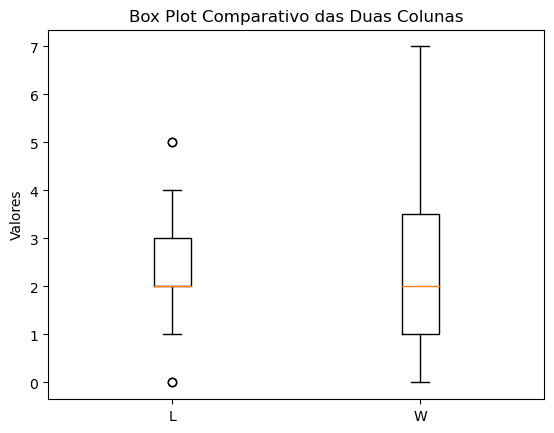

In [467]:
import matplotlib.pyplot as plt
losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()

Analysis of wins + losses on each year on playoffs

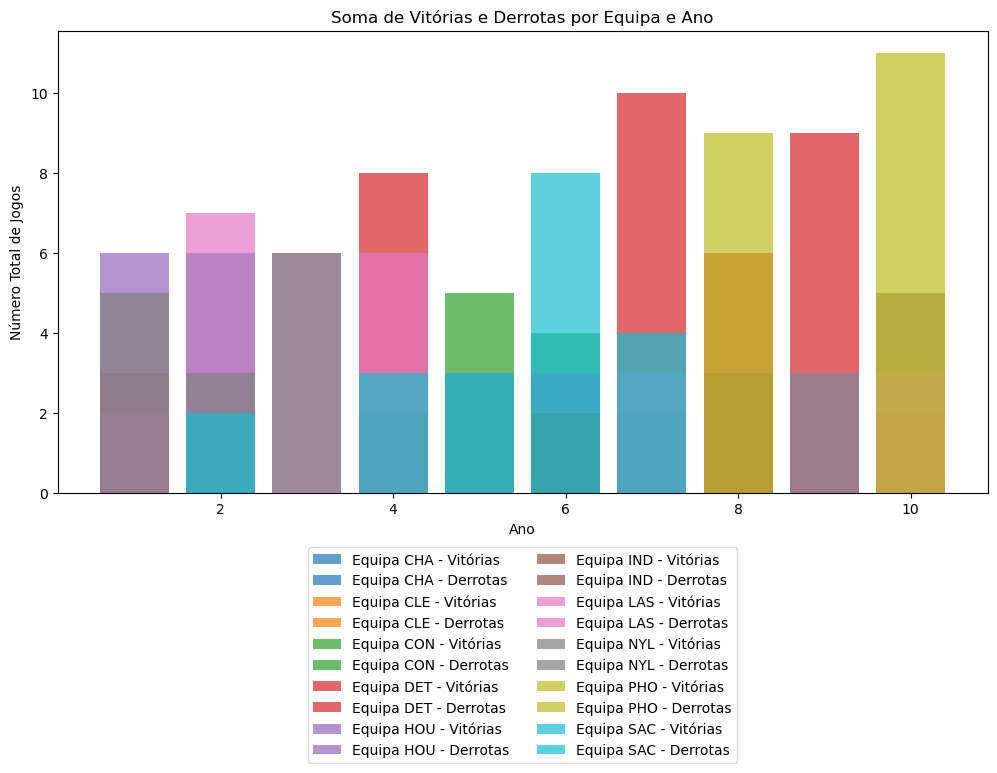

In [468]:
import seaborn as sns

# Suponha que você tenha um DataFrame chamado df com as colunas mencionadas

# Crie um DataFrame com as informações de vitórias e derrotas de cada equipe em cada ano
r = series_data.groupby(['tmIDWinner', 'year'])[['W', 'L']].sum().reset_index()

# dicionário que mapeia cada equipe a uma cor única
team_colors = {team: color for team, color in zip(r['tmIDWinner'].unique(), sns.color_palette())}

# Crie um gráfico de barras empilhadas
plt.figure(figsize=(12, 6))

for team in r['tmIDWinner'].unique():
    if team in team_colors:
        team_data = r[r['tmIDWinner'] == team]
        plt.bar(
            team_data['year'], team_data['W'], label=f'Equipa {team} - Vitórias',
            color=team_colors[team], alpha=0.7
        )
        plt.bar(
            team_data['year'], team_data['L'], label=f'Equipa {team} - Derrotas',
            color=team_colors[team], alpha=0.7, bottom=team_data['W']
        )

plt.xlabel('Ano')
plt.ylabel('Número Total de Jogos')
plt.title('Soma de Vitórias e Derrotas por Equipa e Ano')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.6), ncol=2)
plt.show()


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

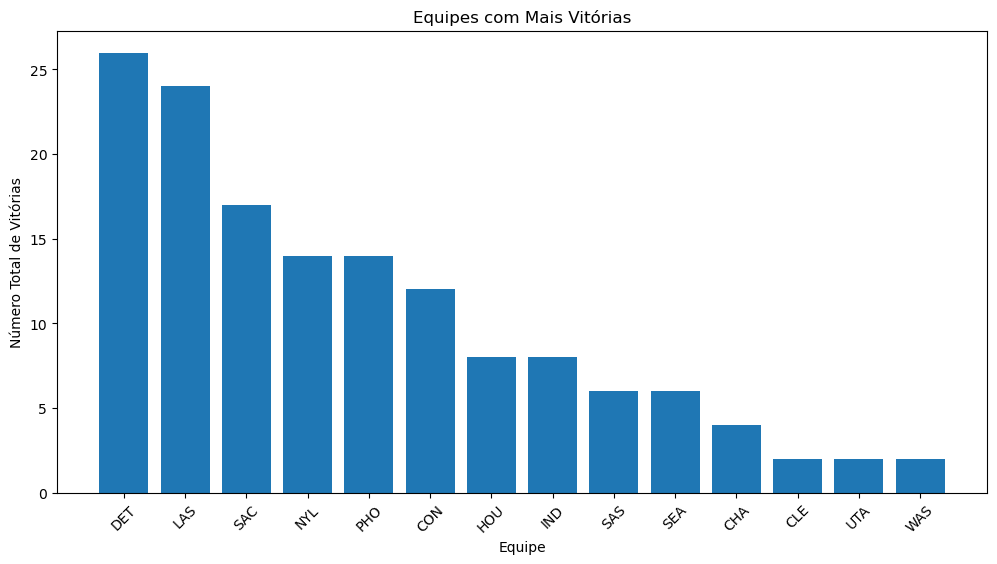

In [469]:
team_wins = series_data.groupby('tmIDWinner')['W'].sum().reset_index()

# Ordene o DataFrame com base no número de vitórias em ordem decrescente
team_wins = team_wins.sort_values(by='W', ascending=False)

# Crie um gráfico de barras mostrando as equipes com mais vitórias
plt.figure(figsize=(12, 6))
plt.bar(team_wins['tmIDWinner'], team_wins['W'])
plt.xlabel('Equipe')
plt.ylabel('Número Total de Vitórias')
plt.title('Equipes com Mais Vitórias')
plt.xticks(rotation=45)

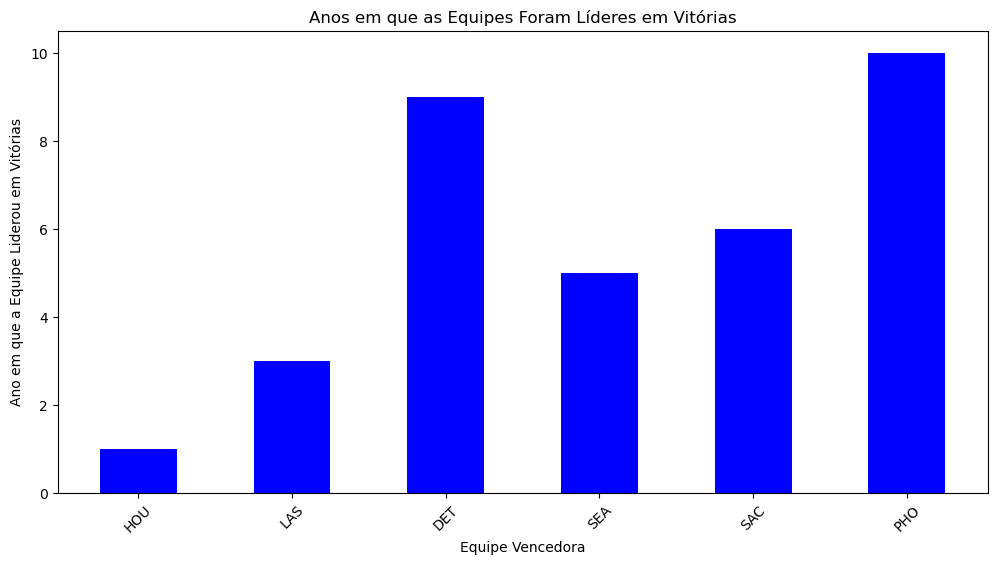

In [470]:
import pandas as pd
import matplotlib.pyplot as plt

# Suponha que você tenha um DataFrame chamado series_data
# com as colunas 'tmIDWinner', 'year', e 'W'

# Agrupe os dados por equipe e ano e some as vitórias para cada equipe em cada ano
team_wins = series_data.groupby(['tmIDWinner', 'year'])['W'].sum().reset_index()

# Encontre a equipe com mais vitórias em cada ano
top_teams = team_wins.loc[team_wins.groupby('year')['W'].idxmax()]

# Crie um gráfico de barras mostrando os anos em que as equipes foram líderes em vitórias
plt.figure(figsize=(12, 6))
plt.bar(top_teams['tmIDWinner'], top_teams['year'], color='blue', width=0.5)  # Largura personalizada das barras
plt.xlabel('Equipa Vencedora')
plt.ylabel('Ano em que a Equipe Liderou em Vitórias')
plt.title('Anos em que as Equipes Foram Líderes em Vitórias')
plt.xticks(rotation=45)  # Rotação dos nomes das equipes para melhor legibilidade

plt.show()
